In [30]:
import sys
sys.path.insert(1, '/home/bricej/MyPythonLibrary/StageM2_IVT/library/')
import domain
from domain import *
from climbas import *
import numpy as np
import xarray as xr
import pandas as pd
from netCDF4 import Dataset
from scipy import stats
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from matplotlib.offsetbox import TextArea, VPacker, AnchoredOffsetbox

# Short period (2000-2019)

In [2]:
iyear = 2000
fyear = 2019

# Long period (1960-2019)

In [3]:
iyear2 = 1960
fyear2 = 2019

# Atmospheric variables

In [4]:
variables = ['t2m','tcwv','sf']

# Subregions with glacier evolution data

In [5]:
domains = ["Tien Shan", "Pamir Alay", "Pamir", "Hindu Kush", "Karakoram", 
           "Kunlun", "Spiti Lahaul", "Central Himalaya","Bhutan", "Nyainqentangla", "Inner TP"]

# Short period trends data loading

Monthly trends of the different armospheric variables in the subregions were computed in : /Stage M2/papier/compute_monthly-trends_var_era5_HIMAPgrouped_final_regions.py for t2m & FLH. For tcwv, ivt & sf in : /Stage M2/papier/compute_monthly-percentage_trends_var_era5_HIMAPgrouped_final_regions.py

In [6]:
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'] # month of the year
path = '/bettik/PROJECTS/pr-regional-climate/bricej/paper/' # path to the data

var_trends = {} # dictionnary to store short period data

for var in variables:
    var_trends[var] = {}
    for month in months :
        monthly_trends = pd.read_csv(f'{path}{var}_era5_{month}_trends_HIMAPgrouped_regions_{iyear}-{fyear}.csv')
        var_trends[var][month] = monthly_trends

# stocker valeur de la pente
var_slopes = {}
for var in variables:
    var_slopes[var] = {}
    for dom in domains:
        var_slopes[var][dom] = {}
        for month in months:
            var_slopes[var][dom][month] = var_trends[var][month].loc[var_trends[var][month]['region'] == dom, 'slope'].values[0] * 10 # *10 -> per decade

# stocker valeur de la pvalue
var_pvalue = {}
for var in variables:
    var_pvalue[var] = {}
    for dom in domains:
        var_pvalue[var][dom] = {}
        for month in months:
            var_pvalue[var][dom][month] = var_trends[var][month].loc[var_trends[var][month]['region'] == dom, 'pvalue'].values[0]

# Long period trends data loading

In [7]:
var_trends_all_period = {} # dictionnary to store long period data

for var in variables:
    var_trends_all_period[var] = {}
    for month in months :
        monthly_trends = pd.read_csv(f'{path}{var}_era5_{month}_trends_HIMAPgrouped_regions_{iyear2}-{fyear2}.csv')
        var_trends_all_period[var][month] = monthly_trends

# stocker valeur de la pente
var_slopes_all_period = {}
for var in variables:
    var_slopes_all_period[var] = {}
    for dom in domains:
        var_slopes_all_period[var][dom] = {}
        for month in months:
            var_slopes_all_period[var][dom][month] = var_trends_all_period[var][month].loc[var_trends_all_period[var][month]['region'] == dom, 'slope'].values[0] * 10 # *10 -> per decade

# stocker valeur de la pvalue
var_pvalue_all_period = {}
for var in variables:
    var_pvalue_all_period[var] = {}
    for dom in domains:
        var_pvalue_all_period[var][dom] = {}
        for month in months:
            var_pvalue_all_period[var][dom][month] = var_trends_all_period[var][month].loc[var_trends_all_period[var][month]['region'] == dom, 'pvalue'].values[0]

# Percentage trend for tcwv, ivt, sf

### Short period

In [8]:
var_trends2 = {} # dictionnary to store short period data percentage

for var in variables:
    var_trends2[var] = {}
    for month in months :
        if var in ['t2m','FLH']: # normal pour t2m & FLH
            monthly_trends = pd.read_csv(f'{path}{var}_era5_{month}_trends_HIMAPgrouped_regions_{iyear}-{fyear}.csv')
        elif var in ['tcwv','ivt','sf']: # percentage trends for tcwv, ivt & sf
            monthly_trends = pd.read_csv(f'{path}{var}_era5_{month}_percentage_trends_HIMAPgrouped_regions_{iyear}-{fyear}.csv')
        var_trends2[var][month] = monthly_trends

# stocker valeur de la pente
var_slopes2 = {}
for var in variables:
    var_slopes2[var] = {}
    for dom in domains:
        var_slopes2[var][dom] = {}
        for month in months:
            var_slopes2[var][dom][month] = var_trends2[var][month].loc[var_trends2[var][month]['region'] == dom, 'slope'].values[0] * 10 # *10 -> per decade

# stocker valeur de la pvalue
var_pvalue2 = {}
for var in variables:
    var_pvalue2[var] = {}
    for dom in domains:
        var_pvalue2[var][dom] = {}
        for month in months:
            var_pvalue2[var][dom][month] = var_trends2[var][month].loc[var_trends2[var][month]['region'] == dom, 'pvalue'].values[0]

### Long period

In [9]:
var_trends_all_period2 = {} # dictionnary to store long period data percentage

for var in variables:
    var_trends_all_period2[var] = {}
    for month in months :
        if var in ['t2m','FLH']: # normal pour t2m & FLH
            monthly_trends = pd.read_csv(f'{path}{var}_era5_{month}_trends_HIMAPgrouped_regions_{iyear2}-{fyear2}.csv')
        elif var in ['tcwv','ivt','sf']: # percentage trends for tcwv, ivt & sf
            monthly_trends = pd.read_csv(f'{path}{var}_era5_{month}_percentage_trends_HIMAPgrouped_regions_{iyear2}-{fyear2}.csv')
        var_trends_all_period2[var][month] = monthly_trends

# stocker valeur de la pente
var_slopes_all_period2 = {}
for var in variables:
    var_slopes_all_period2[var] = {}
    for dom in domains:
        var_slopes_all_period2[var][dom] = {}
        for month in months:
            var_slopes_all_period2[var][dom][month] = var_trends_all_period2[var][month].loc[var_trends_all_period2[var][month]['region'] == dom, 'slope'].values[0] * 10 # *10 -> per decade

# stocker valeur de la pvalue
var_pvalue_all_period2 = {}
for var in variables:
    var_pvalue_all_period2[var] = {}
    for dom in domains:
        var_pvalue_all_period2[var][dom] = {}
        for month in months:
            var_pvalue_all_period2[var][dom][month] = var_trends_all_period2[var][month].loc[var_trends_all_period2[var][month]['region'] == dom, 'pvalue'].values[0]   

# Saison d'accumulation

Mois qui recoivent plus de 8% du total tp annuel. For more details : /StageM2_IVT/papier/Annual_Cycle_var_mean_1960-2019_HIMAPgrouped_final.py (last cell)

In [10]:
tp_season = {"Tien Shan" : ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep'],
        "Pamir Alay" : ['Mar', 'Apr', 'May', 'Jun', 'Jul'],
        "Pamir" : ['Feb', 'Mar', 'Apr', 'May', 'Dec'],
        "Hindu Kush" : ['Feb', 'Mar', 'Apr', 'May', 'Jul', 'Aug'],
        "Karakoram" : ['Feb', 'Mar', 'Apr', 'Jul', 'Aug'],
        "Kunlun" : ['May', 'Jun', 'Jul', 'Aug', 'Sep'],
        "Spiti Lahaul" : ['Feb', 'Mar', 'Apr', 'Jul', 'Aug'],
        "Central Himalaya" : ['Jun', 'Jul', 'Aug', 'Sep'],
        "Bhutan" : ['May', 'Jun', 'Jul', 'Aug', 'Sep'],
        "Nyainqentangla" : ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep'],
        "Inner TP" : ['May', 'Jun', 'Jul', 'Aug', 'Sep']}

# for the plot later we associate the number with the month
month_to_num = {
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4,
    'May': 5, 'Jun': 6, 'Jul': 7, 'Aug': 8,
    'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
}

## Annual trends for the subregions

Annual trends of the different armospheric variables in the subregions were computed in : /Stage M2/papier/compute_annual-trends_var_era5_HIMAPgrouped_final_regions.py for t2m & FLH. For tcwv, ivt & sf in : /Stage M2/papier/compute_annual-percentage_trends_var_era5_HIMAPgrouped_final_regions.py

### Short trend

In [11]:
data_annual = {}
variables = ['t2m','tcwv','sf']

for var in variables:
    if var in ['t2m','FLH','vimd', 'R']: # classic trend with t2m
        data_var = pd.read_csv(f'/bettik/PROJECTS/pr-regional-climate/bricej/paper/{var}_era5_trends_HIMAPgrouped_regions_{iyear}-{fyear}.csv')
        data_var = data_var[["region", "slope", "pvalue"]]
        data_var["slope"] = data_var["slope"] * 10
        data_annual[var] = data_var

    elif var in ['tcwv','ivt','tp','sf','rf']: # percentage trend for sf
        data_var = pd.read_csv(f'/bettik/PROJECTS/pr-regional-climate/bricej/paper/{var}_era5_percentage_trends_HIMAPgrouped_regions_{iyear}-{fyear}.csv')
        data_var = data_var[["region", "slope", "pvalue"]]
        data_var["slope"] = data_var["slope"] * 10
        data_annual[var] = data_var

### Long trend

In [12]:
data_annual2 = {}

for var in variables:
    if var in ['t2m','FLH','vimd', 'R']: # classic trend with t2m
        data_var = pd.read_csv(f'/bettik/PROJECTS/pr-regional-climate/bricej/paper/{var}_era5_trends_HIMAPgrouped_regions_{iyear2}-{fyear2}.csv')
        data_var = data_var[["region", "slope", "pvalue"]]
        data_var["slope"] = data_var["slope"] * 10
        data_annual2[var] = data_var

    elif var in ['tcwv','ivt','tp','sf','rf']: # percentage trend for sf
        data_var = pd.read_csv(f'/bettik/PROJECTS/pr-regional-climate/bricej/paper/{var}_era5_percentage_trends_HIMAPgrouped_regions_{iyear2}-{fyear2}.csv')
        data_var = data_var[["region", "slope", "pvalue"]]
        data_var["slope"] = data_var["slope"] * 10
        data_annual2[var] = data_var

# Final plot : Annual cycle of trends of atmospheric variables

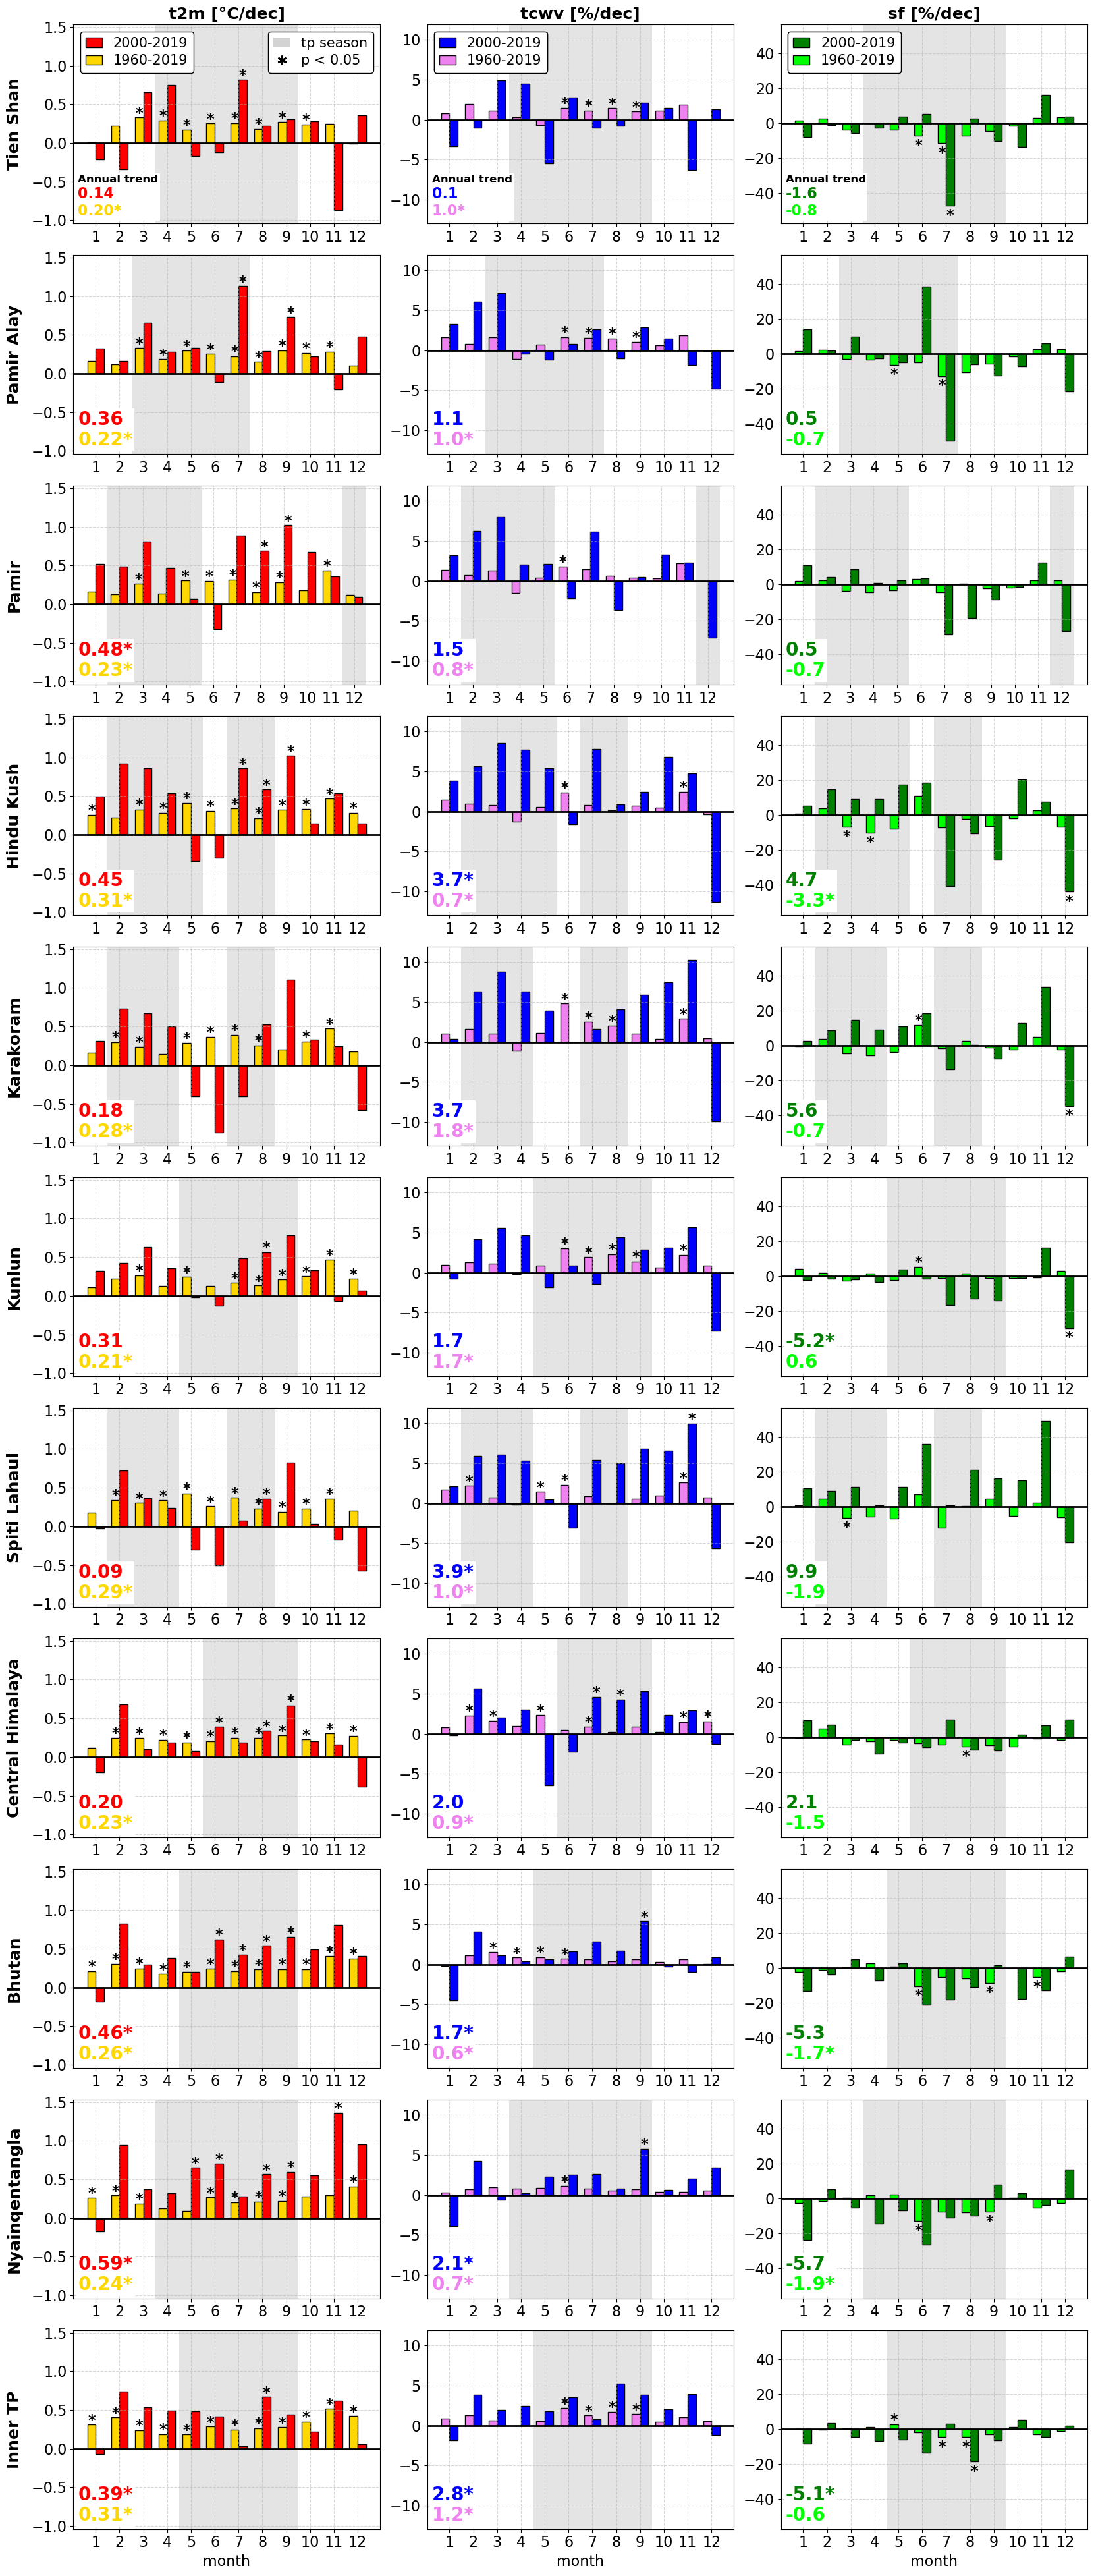

In [38]:
# letters subplots
letter = ['a', 'b', ]

# colors of atmospheric variables dans l'ordre
colors_final = ['red','blue','green'] # short period
colors_final2 = ['gold', 'violet', 'lime'] # long period

# figure
fig, axes = plt.subplots(11, 3, figsize=(16.5, 40))

# limites Y communes par colonne 
ylims = {}
for var in variables:
    all_slopes = []
    for dom in domains:
        all_slopes.extend([var_slopes2[var][dom][m] for m in months])
    ymin = min(all_slopes)
    ymax = max(all_slopes)
    margin = 0.075 * (ymax - ymin)
    ylims[var] = (ymin - margin, ymax + margin)

# matrice des subplots
for i, dom in enumerate(domains): # ligne : domain
    for j, var in enumerate(variables): # colonne : variable
    
        ax = axes[i, j]
        color = colors_final[j] # short period
        color2 = colors_final2[j] # long period
        
            
        # saison de tp
        tp_months = tp_season[dom]
        tp_nums = [month_to_num[m] for m in tp_months]
    
        # trends stats (courte période)
        slopes = [var_slopes2[var][dom][m] for m in months]
        pvalues = [var_pvalue2[var][dom][m] for m in months]
    
        # all period 1960-2019 (longue période)
        slopes_all_period = [var_slopes_all_period2[var][dom][m] for m in months]
        pvalues_all_period = [var_pvalue_all_period2[var][dom][m] for m in months]
    
        # y lim pour chaque colonne
        ax.set_ylim(ylims[var])
        if var == 'FLH':
            ax.set_yticks(np.arange(-100, 200, 50))
        
        # Calcul de l'offset pour espacer l'étoile de la barre (étoile = p-value < 0.05)
        y_range = ylims[var][1] - ylims[var][0]
        offset = 0.02 * y_range
    
        # 0 value
        ax.axhline(y=0, linestyle='-', linewidth=2, color='black', alpha=1, zorder=10)
            
        # mean value of slopes - courte période
        mean = np.mean(slopes)
        # mean value of slopes 1960-2019 - longue période
        mean2 = np.mean(slopes_all_period)
            
        # Construction du barplot juxtaposé
        width = 0.35  # largeur de chaque barre
        for m_idx, month_num in enumerate(range(1, 13)): # m_idx de 0 à 11 et month_num de 1 à 12
            
            # longue période
            p_long = pvalues_all_period[m_idx]
            val_long = slopes_all_period[m_idx]
            ax.bar(month_num - width/2,val_long,width,color=color2,alpha=1.0,edgecolor='black')
            
            # Étoile si p-value significative
            if p_long <= 0.05:
                y_star = val_long + offset if val_long >= 0 else val_long - (2.5*offset)
                ax.text(month_num - width/2, y_star, '*', color='black',fontsize=16, fontweight='bold',ha='center', va='center',zorder=10)
            
            # courte période (alpha=1.0 constant)
            p_short = pvalues[m_idx]
            val_short = slopes[m_idx]
            
            ax.bar(month_num + width/2,val_short,width,color=color,alpha=1.0,edgecolor='black')
            
            # Étoile si p-value significative
            if p_short <= 0.05:
                y_star = val_short + offset if val_short >= 0 else val_short - (2.5*offset)
                ax.text(month_num + width/2, y_star, '*', color='black', fontsize=16, fontweight='bold',ha='center', va='center',zorder=10)
    
        # shading pour tp months (accumulation season)
        for m in tp_nums:
            ax.axvspan(m - 0.5,m + 0.5,color='lightgray',alpha=0.6,zorder=0,ec=None)
        
        # Titre des variables : uniquement tout en haut (première ligne)
        if i == 0:
            if j == 0:
                ax.set_title(f"{var} [°C/dec]", fontsize=18, weight='bold')
            else:
                ax.set_title(f"{var} [%/dec]", fontsize=18, weight='bold')
            
        # Noms des régions (domaines) : à gauche de la première colonne, pivoté à 90°
        if j == 0:
            ax.set_ylabel(dom, fontsize=18, weight='bold', rotation=90, labelpad=10)
    
        # label des mois 
        ax.set_xticks(range(1, 13))
    
        # yticks & labelticks partout
        ax.tick_params(axis='y', labelleft=True, labelsize=16)
        ax.tick_params(axis='x', labelsize=16)
            
        ax.grid(True, linestyle='--', alpha=0.5)

        # Valeurs des pentes annuelles (+ étoile si p-value <= 0.05)
        row_short = data_annual[var].loc[data_annual[var]['region'] == dom]
        row_long  = data_annual2[var].loc[data_annual2[var]['region'] == dom]

        nd = 2 if j == 0 else 1  # décimales : 2 pour la 1re colonne, 1 sinon

        txt_short = f"{row_short['slope'].values[0]:.{nd}f}{'*' if row_short['pvalue'].values[0] <= 0.05 else ''}"
        txt_long  = f"{row_long['slope'].values[0]:.{nd}f}{'*' if row_long['pvalue'].values[0] <= 0.05 else ''}"

        if i == 0:
            fs = 16
        else:
            fs = 20

        children = []

        # Titre uniquement sur la première ligne
        if i == 0:
            children.append(TextArea("Annual trend",
                                     textprops=dict(color='black', fontsize=fs - 4, fontweight='bold')))

        # Valeurs colorées par période
        children.append(TextArea(txt_short, textprops=dict(color=color,  fontsize=fs, fontweight='bold')))
        children.append(TextArea(txt_long,  textprops=dict(color=color2, fontsize=fs, fontweight='bold')))

        block = VPacker(children=children, align='left', pad=0, sep=2)

        anchored = AnchoredOffsetbox(loc='lower left', child=block,
                                     pad=0.2, borderpad=0.3, frameon=True)
        anchored.patch.set_facecolor('white')
        anchored.patch.set_edgecolor('none')
        anchored.patch.set_alpha(1)
        anchored.set_zorder(15)
        ax.add_artist(anchored)

        # légende uniquement sur la première ligne
        if i == 0:
            # Légende 1 : périodes (coin haut-gauche)
            handles_periods = [
                Patch(facecolor=color,  edgecolor='black', label='2000-2019'),
                Patch(facecolor=color2, edgecolor='black', label='1960-2019'),
            ]
            leg1 = ax.legend(handles=handles_periods,
                             loc='upper left',
                             fontsize=15,
                             frameon=True,
                             facecolor='white',
                             edgecolor='black',
                             framealpha=1,
                             handlelength=1.2,
                             borderpad=0.4,
                             labelspacing=0.3)
            leg1.set_zorder(20)
            ax.add_artist(leg1)  # indispensable pour conserver leg1 quand on crée leg2

            # Légende 2 : saison TP + significativité (coin haut-droit)
            if j == 0:
                handles_info = [
                    Patch(facecolor='lightgray', alpha=1.0, edgecolor='none', label='tp season'),
                    Line2D([0], [0], linestyle='None', marker=(6, 2, 0),  # astérisque
                           markersize=10, markeredgewidth=2, color='black', label='p < 0.05'),
                ]
                leg2 = ax.legend(handles=handles_info,
                                 loc='upper right',
                                 fontsize=15,
                                 frameon=True,
                                 facecolor='white',
                                 edgecolor='black',
                                 framealpha=1,
                                 handlelength=1.2,
                                 borderpad=0.4,
                                 labelspacing=0.3)
                leg2.set_zorder(20)

        if i == 10:
            ax.set_xlabel('month', fontsize=16)
        
plt.tight_layout(rect=[0, 0.02, 1, 1]) # Ajustement léger de l'espace bas
plt.show()

Figure 9. Atmospheric monthly trends over regions with limited glacier mass loss : Columns represent the atmospheric variables. t2m : 2m surface temperature (°C.dec⁻¹), FLH : Freezing Level Height (m.dec⁻¹), TCWV : Total Column of Water Vapor (%.dec⁻¹), IVT : Integrated water Vapor Transport (%.dec⁻¹), sf : snow fall (%.dec⁻¹). Rows represent the regions described in Fig. 2. Solid (light) colors indicate trends for 2000–2019 (1960–2019). Annual mean for the two periods are shown by solid and dashed lines, respectively. The light gray shading corresponds to the precipitation (tp, mm.month-1) seasons. A month is considered part of the precipitation season if it contributes more than 8% of the mean annual precipitation total over 1960–2019. 

Figure 10. Atmospheric monthly trends over regions with pronounced glacier mass loss : Same as Fig. 9 but for regions with pronounced mass loss.

Figure A9. Atmospheric monthly trends over Spiti Lahaul and Tien Shan : Same as Fig. 9 but for regions with pronounced mass loss.